# Proyecto final de Química Orgánica — **Compuestos halogenados**
**Fuente de datos:** `tabla_halogenados.xlsx` (hojas *Sustancias*, *Reacciones* y *Obtenciones*).

**Cómo usarlo en Google Colab:** *Entorno de ejecución → Ejecutar todas*. La primera celda de código pide subir el Excel. Cada figura se guarda como PNG (300 ppp) en la carpeta `figuras_halogenados/` para el informe en LaTeX y al final se descarga un .zip.


**Estructura del cuaderno:** antes de cada celda de código hay un texto de **Procedimiento** que explica, paso a paso, qué proceso se realiza y por qué; después de cada gráfica se indica el tipo de gráfica y su interpretación.

## 1. Librerías, estilo y carga del archivo

**Procedimiento.** Esta celda prepara el entorno de trabajo antes de cualquier análisis:

1. **Importa las librerías.** pandas maneja las tablas, numpy hace las operaciones numéricas (logaritmos, raíces), matplotlib y seaborn dibujan las gráficas estáticas, scipy.stats hace las pruebas estadísticas (regresión, Pearson, Spearman, Mann-Whitney) y plotly hace las gráficas interactivas.
2. **Detecta si el cuaderno corre en Google Colab** con un bloque try/except: si existe el módulo google.colab, se usa el botón de subir archivos; si no, se lee el Excel de la carpeta local.
3. **Define un estilo común** para todas las figuras: letra con serifa, sin bordes superior y derecho, cuadrícula gris clara, títulos en negrita a la izquierda y guardado a 300 ppp (la resolución que pide el informe).
4. **Fija la paleta de colores.** Cada propiedad (PM, Pf, Peb, ρ, Pv, μ, solubilidad), cada conjunto (Reacciones en azul petróleo, Obtenciones en mostaza) y cada medio tiene un color fijo, para que el lector reconozca la misma variable en todas las gráficas.
5. **Crea la carpeta** figuras_halogenados/ y **carga el Excel**: si la variable URL tiene el enlace del archivo en GitHub, se convierte en enlace *raw* y se descarga; si está vacía, Colab pide subir el archivo.

In [ ]:
# Relación que se prepara: ninguna todavía; esta celda carga las herramientas y el estilo común a todas las gráficas.
import os, shutil                      # os crea carpetas; shutil comprime las figuras en un .zip
import urllib.request                  # descarga archivos desde internet (el Excel en GitHub)
import numpy as np                     # numpy: operaciones numéricas (logaritmos, raíces, arreglos)
import pandas as pd                    # pandas: tablas (DataFrames) leídas desde Excel
import matplotlib.pyplot as plt        # matplotlib: motor de dibujo de todas las figuras
import seaborn as sns                  # seaborn: gráficas estadísticas sobre matplotlib
from matplotlib.colors import LinearSegmentedColormap   # para construir escalas de color propias
from scipy import stats                # scipy.stats: regresión lineal, Pearson, Spearman, Mann-Whitney
import plotly.express as px            # plotly: gráficas interactivas (pasar el cursor sobre los puntos)

# try/except: si el cuaderno corre en Colab se usa el botón para subir archivos; si no, se lee el archivo local.
try:
    from google.colab import files     # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:                    # fuera de Colab no existe ese módulo y se cae aquí
    EN_COLAB = False

from matplotlib import font_manager    # para revisar qué tipografías están instaladas
sns.set_theme(style='ticks', font_scale=1.0)          # fondo limpio, sin cuadrícula fuerte
instaladas = {f.name for f in font_manager.fontManager.ttflist}        # nombres de fuentes disponibles
FUENTE = [f for f in ['DejaVu Serif'] if f in instaladas] + ['DejaVu Sans']   # si falta, usa DejaVu Sans
plt.rcParams.update({
    'font.family': FUENTE,                                  # tipografía propia de este proyecto
    'axes.spines.top': False, 'axes.spines.right': False,   # se quitan los bordes que no aportan
    'axes.grid': True, 'grid.color': '#EDEDED', 'grid.linewidth': 0.6,  # cuadrícula suave
    'savefig.dpi': 300, 'figure.dpi': 100,                  # 300 ppp para el informe en LaTeX
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

# Colores fijos: la misma variable tiene el mismo color en todas las gráficas.
COL_VAR = {'PM': '#1F5F6B', 'Pf': '#7A8C99', 'Peb': '#B5654A', 'ρ': '#C99A2E', 'Pv': '#5E7F8C', 'μ': '#8C4F3F', 'Sol': '#4C9AA8'}
COL_CONJ = {'Reacciones': '#1F5F6B', 'Obtenciones': '#C99A2E'}                 # reacciones (sustancia como reactivo) vs. obtenciones (como producto)
COL_MEDIO = {'Ácido': '#B5654A', 'Básico': '#1F5F6B', 'Neutro': '#A9B1B8', 'Apolar': '#C99A2E'}               # medio de reacción
COL_SI = {'cat': '#4D4D4D', 'calor': '#A3708F'}                   # colores para las variables sí/no (catalizador, calor)
GRIS = '#9E9E9E'                       # gris para lo secundario (líneas de referencia, puntos de fondo)
DIV = LinearSegmentedColormap.from_list('div', ['#6F8FA6', '#E3E3E3', '#B5654A'])   # divergente suave con centro gris claro
SEQ = sns.light_palette('#1F5F6B', as_cmap=True)            # secuencial: claro = bajo, oscuro = alto

CARPETA = 'figuras_halogenados'             # carpeta donde se guardan los PNG
os.makedirs(CARPETA, exist_ok=True)    # exist_ok=True evita error si la carpeta ya existe

# Lectura del Excel desde GitHub: pegar entre las comillas el enlace del archivo en el repositorio.
URL = ''                               # ejemplo: https://github.com/USUARIO/REPOSITORIO/blob/main/datos/tabla_halogenados.xlsx
ARCHIVO = 'tabla_halogenados.xlsx'
if URL:                                # if: si hay enlace, se descarga el Excel desde GitHub
    URL = URL.replace('github.com', 'raw.githubusercontent.com').replace('/blob/', '/')   # enlace directo al archivo
    urllib.request.urlretrieve(URL, ARCHIVO)          # descarga y guarda con el nombre ARCHIVO
elif EN_COLAB and not os.path.exists(ARCHIVO):        # elif: sin enlace, se sube a mano en Colab
    subido = files.upload()            # devuelve un diccionario {nombre: contenido}
    ARCHIVO = [n for n in subido if n.endswith('.xlsx')][0]   # toma el primer .xlsx subido
print('Archivo:', ARCHIVO)

Archivo: tabla_halogenados.xlsx


## 2. Lectura y revisión de los datos
La tabla ya viene organizada desde Excel (sin celdas combinadas, unidades solo en el encabezado; los datos que no existen están escritos como NA (no aplica) y pandas los lee como vacíos (NaN)). Aquí solo se verifica: se quitan espacios, se fuerza el tipo numérico y se cuentan los datos faltantes.

**Procedimiento.** Lectura y limpieza de las tres hojas del Excel:

1. pd.read_excel(..., sheet_name=None lee **todas las hojas a la vez** y las guarda en sus (10 sustancias), rea (reacciones, con sus pasos) y obt (obtenciones, con sus pasos).
2. En las columnas de texto se **quitan los espacios sobrantes** (str.strip), para que, por ejemplo, "Básico " y "Básico" no se cuenten como medios distintos.
3. Las columnas numéricas (propiedades, temperatura, tiempo y presión) se convierten a número con pd.to_numeric(..., errors='coerce'). Así **el texto NA se transforma en NaN**, el valor vacío que pandas excluye de los cálculos en lugar de tratarlo como cero.
4. Se **acortan los nombres** de las columnas (por ejemplo, "Peb (°C)" pasa a "Peb") y se guarda un diccionario con la unidad de cada una para rotular los ejes.
5. Se imprime el **número de filas por hoja y de datos faltantes por columna**, que es el control de calidad de la tabla antes de graficar.

In [ ]:
# Relación que se prepara: se leen las 3 tablas que luego se cruzan por la columna "Sustancia".
hojas = pd.read_excel(ARCHIVO, sheet_name=None)        # sheet_name=None lee TODAS las hojas en un diccionario
sus, rea, obt = hojas['Sustancias'], hojas['Reacciones'], hojas['Obtenciones']

NUM = ['PM (g/mol)', 'Pf (°C)', 'Peb (°C)', 'ρ (g/cm³)', 'pKa', 'μ (D)', 'Solubilidad (mol/L)', 'Pv (Pa)',
       'T (°C)', 't (h)', 'P (bar)']                     # columnas que deben ser numéricas
for df in (sus, rea, obt):                              # for: repite la misma limpieza en las 3 tablas
    for col in df.columns:
        if df[col].dtype == object:                     # if: solo las columnas de texto
            df[col] = df[col].str.strip()               # quita espacios al inicio y al final
    for col in NUM:
        if col in df.columns:                           # no todas las hojas tienen todas las columnas
            df[col] = pd.to_numeric(df[col], errors='coerce')   # texto que no sea número → NaN (vacío)

# Nombres cortos para escribir el código más fácil (las unidades se ponen en los ejes).
CORTO = {'PM (g/mol)': 'PM', 'Pf (°C)': 'Pf', 'Peb (°C)': 'Peb', 'ρ (g/cm³)': 'ρ', 'pKa': 'pKa', 'μ (D)': 'μ',
         'Solubilidad (mol/L)': 'Sol', 'Pv (Pa)': 'Pv', 'T (°C)': 'T', 't (h)': 't', 'P (bar)': 'P'}
sus, rea, obt = (d.rename(columns=CORTO) for d in (sus, rea, obt))
UNIDAD = {'PM': 'PM (g/mol)', 'Pf': 'Pf (°C)', 'Peb': 'Peb (°C)', 'ρ': 'ρ (g/cm³)', 'pKa': 'pKa',
          'μ': 'μ (D)', 'Sol': 'Solubilidad (mol/L)', 'Pv': 'Pv (Pa)'}
PROPS = list(UNIDAD)                                    # lista de las 8 propiedades

print('Filas:', {'Sustancias': len(sus), 'Reacciones': len(rea), 'Obtenciones': len(obt)})
print('\nCeldas vacías por columna numérica (NaN):')
print(pd.DataFrame({n: d[[c for c in PROPS + ['T', 't', 'P'] if c in d]].isna().sum()
                    for n, d in (('Sustancias', sus), ('Reacciones', rea), ('Obtenciones', obt))}))

Filas: {'Sustancias': 10, 'Reacciones': 139, 'Obtenciones': 109}

Celdas vacías por columna numérica (NaN):
     Sustancias  Reacciones  Obtenciones
P           NaN         137           94
PM          0.0          39            9
Peb         0.0          46           10
Pf          1.0         115           30
Pv          0.0          46           10
Sol         0.0          44           10
T           NaN          48           47
pKa         9.0          98           56
t           NaN          59           58
μ           4.0         137           62
ρ           0.0          44            9


**Procedimiento.** Esta celda cambia la unidad de análisis de **paso** a **reacción** y define las herramientas que usan todas las gráficas.

1. **Función por_reaccion.** En el Excel, una reacción puede ocupar varias filas (una por paso). La función conserva la fila del paso 1, donde están el producto y sus propiedades, y le agrega: la **temperatura máxima** de todos sus pasos (T_max, agrupando por ID), si **usa catalizador** en alguno de sus pasos (cualquier columna "Catalizador" con dato) y el **conjunto** al que pertenece.
2. Se aplica a las dos hojas: rx (reacciones), ob (obtenciones) y `ambos` (las dos juntas, para compararlas).
3. ORDEN ordena las 10 sustancias por **peso molecular**, del fluoroetano al bromociclohexano; ese orden se repite en todos los ejes. MEDIOS guarda los medios que sí aparecen en los datos.
4. **Función wilson.** Calcula una proporción p = k/n y su **intervalo de confianza del 95 % de Wilson**. Se usa Wilson y no el intervalo normal porque con n pequeño (10 reacciones por sustancia) o con p cercano a 0 o a 1 el intervalo normal puede salirse del rango 0–1.
5. **Función guardar.** Guarda cada figura como PNG en la carpeta de figuras.
6. **Función regresion.** Ajusta una recta por mínimos cuadrados (linregress), calcula la correlación de **Pearson** (lineal) y de **Spearman** (por rangos, resistente a valores extremos), dibuja la dispersión con la recta y escribe la ecuación, R² y el valor p.

In [ ]:
# Relación que se prepara: una fila por reacción (las reacciones de varios pasos ocupan varias filas en Excel).
def por_reaccion(df, conj):
    # Las propiedades están solo en la fila del paso 1; la temperatura máxima se toma de todos los pasos.
    p1 = df[df['Paso'] == 1].copy()                            # una fila por reacción
    p1['T_max'] = p1['ID'].map(df.groupby('ID')['T'].max())  # máximo de T entre los pasos (ignora NaN)
    cat = df.filter(like='Catalizador').notna().any(axis=1)   # True si la fila tiene algún catalizador
    p1['Usa catalizador'] = p1['ID'].map(cat.groupby(df['ID']).any())
    p1['Conjunto'] = conj                                      # etiqueta: Reacciones u Obtenciones
    return p1

rx = por_reaccion(rea, 'Reacciones')        # productos de las reacciones (sustancia como reactivo)
ob = por_reaccion(obt, 'Obtenciones')       # reactivos de las obtenciones (sustancia como producto)
ambos = pd.concat([rx, ob], ignore_index=True)

ORDEN = sus.sort_values('PM')['Sustancia'].tolist()   # sustancias ordenadas por peso molecular
MEDIOS = [m for m in ['Ácido', 'Básico', 'Neutro', 'Apolar'] if m in set(ambos['Medio'].dropna())]
print('Reacciones:', len(rx), '| Obtenciones:', len(ob))
print('Orden por PM:', ORDEN)

def wilson(k, n, z=1.96):
    # Intervalo de confianza de Wilson (95 %) para una proporción k/n; funciona bien con n pequeño.
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    ancho = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, centro - ancho, centro + ancho

def guardar(fig, nombre):
    fig.savefig(f'{CARPETA}/{nombre}.png', bbox_inches='tight')   # bbox_inches='tight' evita recortes

def regresion(d, x, y, ylab, titulo, nombre, grupo=None):
    # Dispersión + recta de regresión lineal con su ecuación, R², p, Pearson y Spearman (se usa en 3 gráficas).
    res = stats.linregress(d[x], d[y])               # pendiente, intercepto, r y p de la recta
    rp, pp = stats.pearsonr(d[x], d[y])              # Pearson: relación lineal
    rs, ps = stats.spearmanr(d[x], d[y])             # Spearman: relación monótona, menos sensible a atípicos
    fig, ax = plt.subplots(figsize=(9, 5.8), constrained_layout=True)
    if grupo:                                        # if: colorea los puntos por conjunto si se pide
        sns.scatterplot(data=d, x=x, y=y, hue=grupo, palette=COL_CONJ, s=45, alpha=0.75, edgecolor='white', ax=ax)
    else:
        sns.scatterplot(data=d, x=x, y=y, color=COL_VAR[x], s=45, alpha=0.75, edgecolor='white', ax=ax)
    xs = np.linspace(d[x].min(), d[x].max(), 100)    # 100 puntos para dibujar la recta
    ax.plot(xs, res.intercept + res.slope * xs, color=COL_VAR[y], lw=1.8,
            label=f'y = {res.slope:.3g}x {res.intercept:+.3g}  (R² = {res.rvalue**2:.2f}, p = {res.pvalue:.1e})')
    ax.set_xlabel(UNIDAD[x]); ax.set_ylabel(ylab); ax.set_title(titulo)
    ax.legend(fontsize=8, frameon=False)
    guardar(fig, nombre); plt.show()
    print(f'n = {len(d)} | y = {res.slope:.4g}x {res.intercept:+.4g} | R² = {res.rvalue**2:.3f} | p = {res.pvalue:.2e}')
    print(f'Pearson r = {rp:.2f} (p = {pp:.1e}) | Spearman ρ = {rs:.2f} (p = {ps:.1e})')

Reacciones: 100 | Obtenciones: 100
Orden por PM: ['Fluoroetano', 'Clorometano', 'Fluoruro de acetilo', 'Cloruro de formilo', 'Diclorometano', 'Bromoetano', 'Cloroformo', 'Bromuro de acetilo', 'Tetracloruro de carbono', 'Bromociclohexano']


## 3. Análisis gráfico

### Gráfica 1. Mapa de calor de correlación entre propiedades

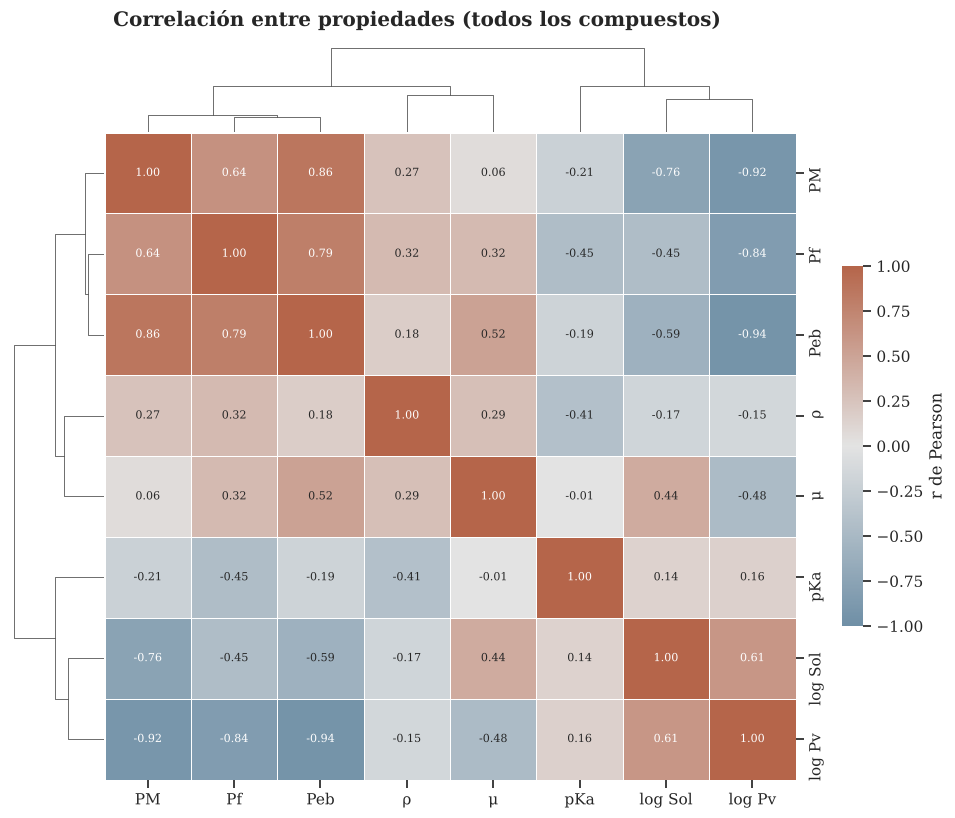

Número mínimo de compuestos por pareja: 15
Parejas más fuertes (|r|):
Peb  log Pv    -0.94
PM   log Pv    -0.92
     Peb        0.86
Pf   log Pv    -0.84
     Peb        0.79
PM   log Sol   -0.76


In [ ]:
# Relación química: qué propiedades varían juntas. Se leen primero los valores cercanos a 1 o a -1
# para elegir las parejas que se grafican después (por ejemplo PM–Peb por las fuerzas de London).
# Se usan TODOS los compuestos distintos del Excel (sustancias, productos y reactivos, sin repetir CAS)
# para tener más datos por pareja; la relación entre propiedades no depende del papel en la reacción.
comp = pd.concat([sus.rename(columns={'Sustancia': 'Nombre'}),
                  rx.rename(columns={'Producto': 'Nombre', 'CAS producto': 'CAS'}),
                  ob.rename(columns={'Reactante principal': 'Nombre', 'CAS reactante': 'CAS'})])
comp = comp.drop_duplicates(subset='CAS')[PROPS].copy()      # un compuesto = una fila
comp['Pv'] = np.log10(comp['Pv'].where(comp['Pv'] > 0))       # log10: Pv abarca muchos órdenes de magnitud
comp['Sol'] = np.log10(comp['Sol'].where(comp['Sol'] > 0))    # igual para la solubilidad
comp = comp.rename(columns={'Pv': 'log Pv', 'Sol': 'log Sol'})

corr = comp.corr(method='pearson', min_periods=5)   # min_periods=5: con menos de 5 pares no se calcula
n_par = comp.notna().astype(int).T @ comp.notna().astype(int)   # n de compuestos con ambos datos
sin_dato = corr.columns[corr.isna().any()]          # variables con alguna pareja sin cálculo
if len(sin_dato):                                   # if: el dendrograma no admite celdas vacías
    print('Se excluyen por falta de pares (n < 5):', list(sin_dato))
    corr = corr.drop(index=sin_dato, columns=sin_dato); n_par = n_par.loc[corr.index, corr.columns]

g = sns.clustermap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
                   annot_kws={'size': 8}, linewidths=0.6, linecolor='white', figsize=(8.5, 8),
                   dendrogram_ratio=0.12, cbar_pos=(1.0, 0.25, 0.025, 0.45),
                   cbar_kws={'label': 'r de Pearson'})   # matriz completa y cuadrada, sin máscara
g.ax_heatmap.set_xlabel(''); g.ax_heatmap.set_ylabel('')     # los nombres ya están en las marcas
g.figure.suptitle('Correlación entre propiedades', y=1.02, fontweight='bold')
guardar(g.figure, '01_mapa_correlacion'); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()   # cada pareja una sola vez
print('Número mínimo de compuestos por pareja:', int(n_par.values.min()))
print('Parejas más fuertes (|r|):')
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(6).round(2).to_string())

**Tipo de gráfica.** Mapa de calor con dendrograma. El color resume el coeficiente r de Pearson de cada pareja y el árbol de la izquierda y de arriba reúne las propiedades con comportamiento similar. Paleta divergente suave: azul grisáceo (negativo), gris claro (cero) y terracota (positivo).

**Interpretación.** Las parejas más fuertes son Peb–log Pv (r = −0.94) y PM–log Pv (r = −0.92): los compuestos halogenados más pesados se evaporan mucho menos. PM–Peb (r = 0.86) refleja que el halógeno aporta masa y polarizabilidad, y con ellas fuerzas de London más intensas. La densidad casi no se relaciona con el PM (r = 0.27): depende de cuántos halógenos hay por volumen, no solo de la masa. El dendrograma separa un bloque de tamaño y ebullición (PM, Pf, Peb) de otro de volatilidad y solubilidad (log Pv, log Sol)

### Gráfica 2. Frecuencia de cada tipo de reacción: reacciones frente a obtenciones

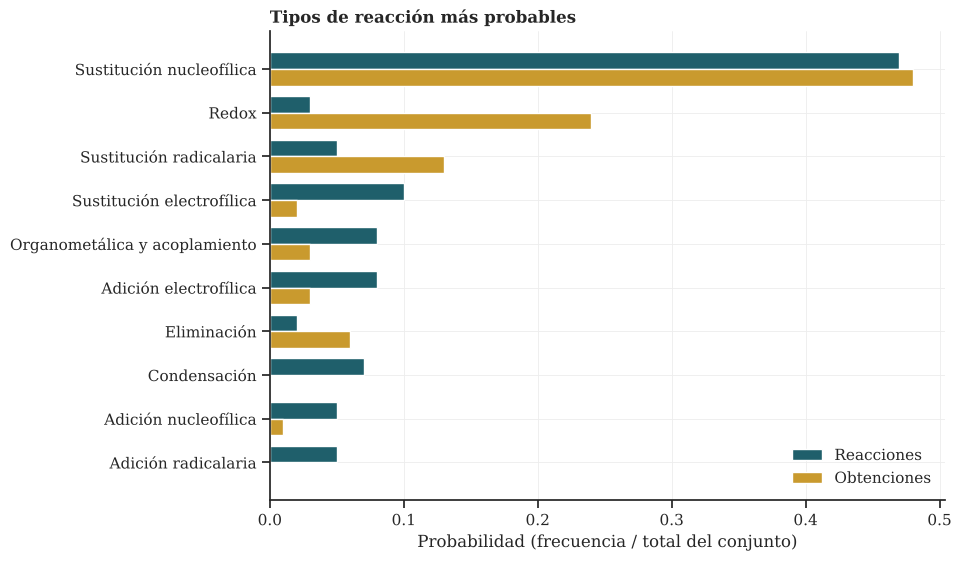

Conjunto                       Obtenciones  Reacciones
Tipo de reacción                                      
Sustitución nucleofílica                48          47
Redox                                   24           3
Sustitución radicalaria                 13           5
Sustitución electrofílica                2          10
Organometálica y acoplamiento            3           8
Adición electrofílica                    3           8
Eliminación                              6           2
Condensación                             0           7
Adición nucleofílica                     1           5
Adición radicalaria                      0           5


In [ ]:
# Relación química: qué tipo de transformación es más probable cuando la sustancia reacciona (reactivo)
# y cuando se forma (producto). Variable categórica → barras AGRUPADAS (no apiladas), sin números encima.
tabla = pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto'], normalize='columns')   # proporciones
orden = tabla.sum(axis=1).sort_values(ascending=False).index.tolist()                        # de mayor a menor
tabla = tabla.loc[orden]

fig, ax = plt.subplots(figsize=(9.5, 5.5), constrained_layout=True)
y = np.arange(len(orden)); h = 0.38                      # posiciones de las barras horizontales
for i, conj in enumerate(['Reacciones', 'Obtenciones']):
    ax.barh(y + (i - 0.5) * h, tabla[conj], height=h, color=COL_CONJ[conj], label=conj)
ax.set_yticks(y); ax.set_yticklabels(orden); ax.invert_yaxis()
ax.set_xlabel('Probabilidad (frecuencia / total del conjunto)'); ax.set_ylabel('')
ax.set_title('Tipos de reacción más probables'); ax.legend(frameon=False)
guardar(fig, '02_tipos_reaccion'); plt.show()
print(pd.crosstab(ambos['Tipo de reacción'], ambos['Conjunto']).loc[orden].to_string())

**Tipo de gráfica.** Gráfico de barras agrupadas: variable categórica (tipo de reacción) en dos conjuntos; se usan proporciones porque cada conjunto tiene su propio total.

**Interpretación.** Cada reacción se clasificó por su mecanismo principal. Además de los 9 tipos del profesor se necesitó **organometálica y acoplamiento**, para los procesos mediados por metales (acoplamientos de Negishi y Kumada, homologación de Matteson, carbonilaciones). La **sustitución nucleofílica** domina tanto cuando los halogenados reaccionan (47 %) como cuando se obtienen (48 %): el halógeno es un buen grupo saliente y también entra como nucleófilo (X⁻). Para obtenerlos le siguen el **redox (24 %)**, sobre todo hidrodecloraciones y cloraciones oxidativas, y la **sustitución radicalaria (13 %)**, la halogenación clásica de alcanos con luz o calor. Al reaccionar aparece la **sustitución electrofílica (10 %)**: alquilaciones y acilaciones de Friedel-Crafts.

### Gráfica 3. Probabilidad del medio de reacción

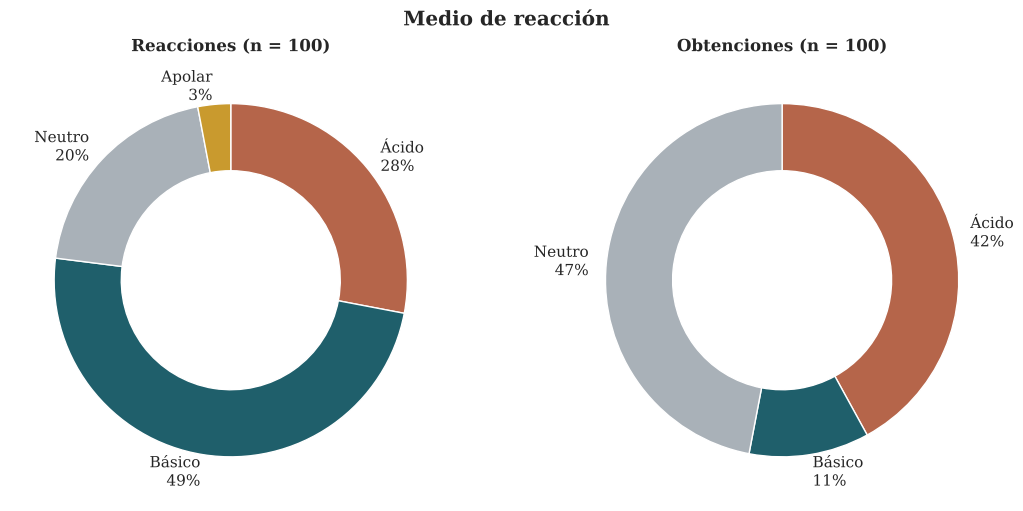

   Conjunto  Medio  n    P   lo   hi
Obtenciones  Ácido 42 0.42 0.33 0.52
Obtenciones Básico 11 0.11 0.06 0.19
Obtenciones Neutro 47 0.47 0.38 0.57
Obtenciones Apolar  0 0.00 0.00 0.04
 Reacciones  Ácido 28 0.28 0.20 0.37
 Reacciones Básico 49 0.49 0.39 0.59
 Reacciones Neutro 20 0.20 0.13 0.29
 Reacciones Apolar  3 0.03 0.01 0.08


In [ ]:
# Relación química: en qué medio (ácido, básico, neutro o apolar) ocurren las reacciones de estas sustancias.
# Es categórica con 4 categorías; se calcula la probabilidad con su intervalo de confianza de Wilson.
filas = []
for conj, g in ambos.groupby('Conjunto'):            # for: un cálculo por conjunto
    n_tot = g['Medio'].notna().sum()                  # solo reacciones con medio conocido
    for m in MEDIOS:
        p, lo, hi = wilson((g['Medio'] == m).sum(), n_tot)
        filas.append(dict(Conjunto=conj, Medio=m, n=int((g['Medio'] == m).sum()), P=p, lo=lo, hi=hi))
res = pd.DataFrame(filas)

fig, axs = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, conj in zip(axs, ['Reacciones', 'Obtenciones']):   # una dona por conjunto (4 categorías ≤ 5)
    cnt = ambos[ambos['Conjunto'] == conj]['Medio'].value_counts().reindex(MEDIOS).fillna(0)
    cnt = cnt[cnt > 0]                                     # un medio con 0 casos no se dibuja
    ax.pie(cnt, labels=[f'{m}\n{p:.0%}' for m, p in zip(cnt.index, cnt / cnt.sum())],
           colors=[COL_MEDIO[m] for m in cnt.index], startangle=90, counterclock=False,
           wedgeprops={'width': 0.38, 'edgecolor': 'white'})
    ax.set_title(f'{conj} (n = {int(cnt.sum())})', loc='center')
fig.suptitle('Medio de reacción', fontweight='bold')
guardar(fig, '03_medio_reaccion'); plt.show()
print(res.round(2).to_string(index=False))

**Tipo de gráfica.** Gráfico de anillo: solo 4 categorías (≤ 5) que suman el total de cada conjunto. Los IC 95 % de Wilson se imprimen en la tabla del código.

**Interpretación.** En las reacciones domina el medio **básico (0.49, IC 0.39–0.59)**: la sustitución nucleofílica y la acilación usan una base para neutralizar el HX que se libera. En las obtenciones dominan el **neutro (0.47)** y el **ácido (0.42)**

### Gráfica 4. Burbujas: solvente frente a tipo de reacción

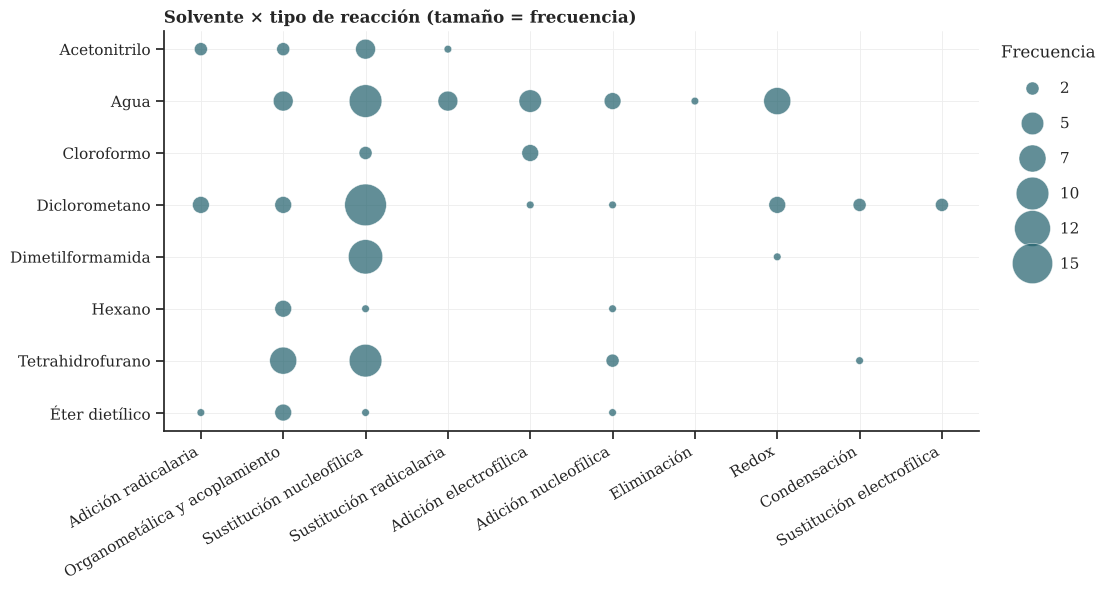

        Solvente              Tipo de reacción  n
   Diclorometano      Sustitución nucleofílica 16
Dimetilformamida      Sustitución nucleofílica 11
            Agua      Sustitución nucleofílica 10
Tetrahidrofurano      Sustitución nucleofílica 10
Tetrahidrofurano Organometálica y acoplamiento  7
Total de solventes distintos: 27


In [ ]:
# Relación química: qué solvente se usa con cada tipo de reacción (polaridad del solvente vs. mecanismo).
# Hay muchos solventes, así que se toman los 8 más frecuentes; el tamaño de la burbuja = frecuencia
# (la burbuja más grande es la combinación más probable).
filas = [rea, obt]
largo = pd.concat([d.melt(id_vars=['ID', 'Tipo de reacción'], value_vars=[c for c in d if c.startswith('Solvente')],
                          value_name='Solvente').dropna(subset=['Solvente']) for d in filas])
top = largo['Solvente'].value_counts().head(8).index        # 8 solventes más usados
t = largo[largo['Solvente'].isin(top)].groupby(['Solvente', 'Tipo de reacción']).size().reset_index(name='n')
fig, ax = plt.subplots(figsize=(11, 5.8), constrained_layout=True)
sns.scatterplot(data=t, x='Tipo de reacción', y='Solvente', size='n', sizes=(30, 900), color=COL_VAR['PM'],
                alpha=0.7, edgecolor='white', legend='brief', ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Solvente × tipo de reacción (tamaño = frecuencia)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(title='Frecuencia', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False, labelspacing=1.3)
guardar(fig, '04_burbujas_solvente_tipo'); plt.show()
print(t.sort_values('n', ascending=False).head(5).to_string(index=False))
print('Total de solventes distintos:', largo['Solvente'].nunique())

**Tipo de gráfica.** Gráfico de burbujas en matriz: dos variables categóricas; el área de la burbuja es la frecuencia.

**Interpretación.** La burbuja mayor es el **diclorometano en sustitución nucleofílica (16)**, seguida de dimetilformamida (11), agua (10) y THF (10) en el mismo tipo. La DMF es polar aprótica y favorece la SN2 porque no solvata al nucleófilo; el diclorometano disuelve bien a los sustratos orgánicos sin reaccionar. El THF también aparece en lo organometálico (7), porque estabiliza los reactivos de magnesio, zinc y litio.

### Gráfica 5. Relación sustancia × tipo de reacción

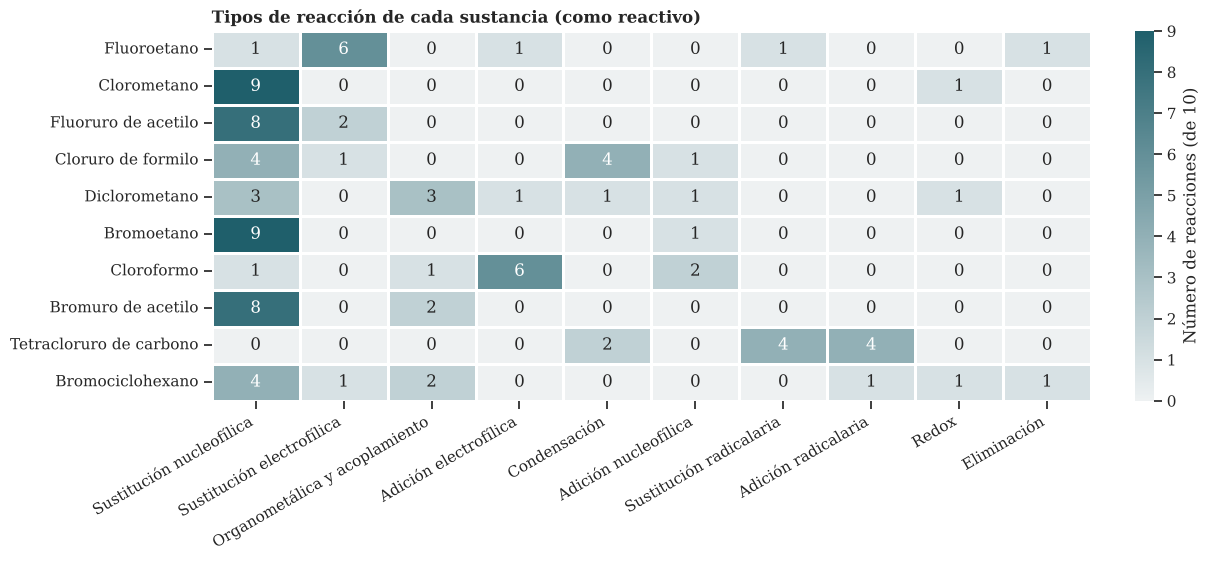

In [ ]:
# Relación química: qué tipo de reacción es típico de cada sustancia (reactividad según su estructura).
t = pd.crosstab(rx['Sustancia'], rx['Tipo de reacción']).reindex(index=ORDEN, fill_value=0)
t = t[t.sum().sort_values(ascending=False).index]          # columnas de la familia más a la menos frecuente
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Número de reacciones (de 10)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Tipos de reacción de cada sustancia (como reactivo)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '05_sustancia_tipo'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia: cruza dos variables categóricas; el número de cada celda es la frecuencia (de 10 reacciones).

**Interpretación.** Los haluros de alquilo reaccionan por sustitución nucleofílica: clorometano y bromoetano 9 de 10 (SN2 sobre un carbono poco impedido). Los haluros de acilo hacen sustitución nucleofílica en el acilo: fluoruro de acetilo 8 y bromuro de acetilo 8. El fluoroetano reacciona sobre todo por sustitución electrofílica (6, Friedel-Crafts con SbF₅), el cloroformo por adición electrofílica (6, diclorocarbeno) y el tetracloruro de carbono por vía radicalaria (4 sustituciones y 4 adiciones, reacción de Kharasch).

### Gráfica 6. Relación sustancia × medio de reacción

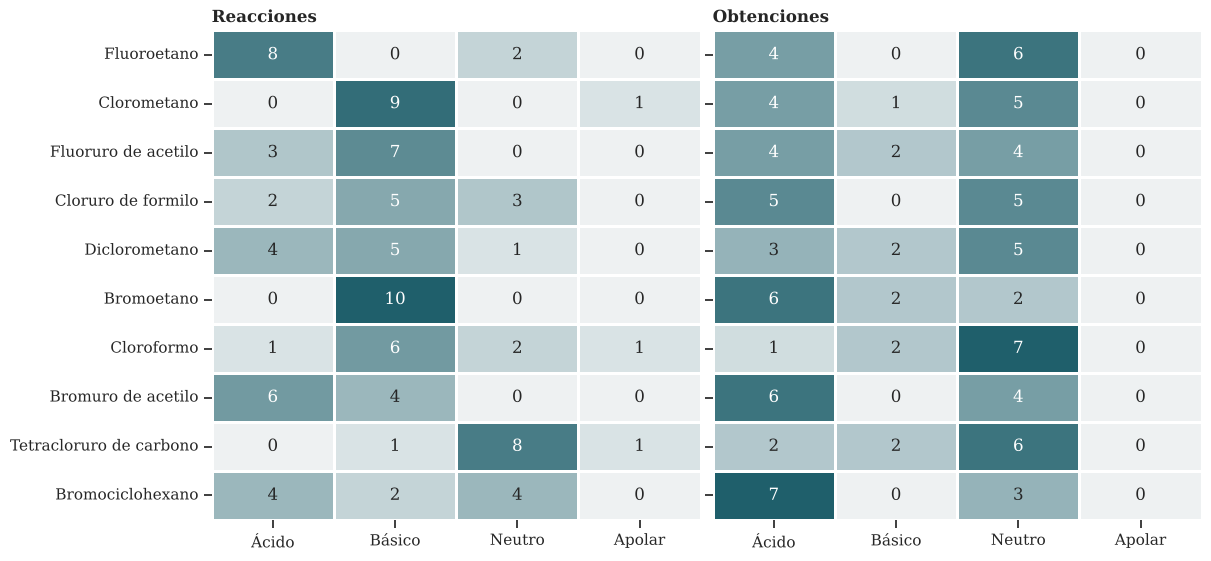

In [ ]:
# Relación química: cada sustancia prefiere ciertos medios según sus grupos funcionales (dos variables
# categóricas → tabla de frecuencias en mapa de calor). Escala secuencial: claro = pocas, oscuro = muchas.
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, constrained_layout=True)
for ax, conj in zip(axs, ['Reacciones', 'Obtenciones']):
    t = pd.crosstab(ambos[ambos['Conjunto'] == conj]['Sustancia'], ambos[ambos['Conjunto'] == conj]['Medio'])
    t = t.reindex(index=ORDEN, columns=MEDIOS, fill_value=0)   # mismas filas y columnas en ambos paneles
    sns.heatmap(t, cmap=SEQ, annot=True, fmt='d', linewidths=0.8, linecolor='white', cbar=False, ax=ax)
    ax.set_title(conj); ax.set_xlabel(''); ax.set_ylabel('')
guardar(fig, '06_sustancia_medio'); plt.show()

**Tipo de gráfica.** Mapa de calor de una tabla de contingencia, un panel para reacciones y otro para obtenciones.

**Interpretación.** El bromoetano reacciona en medio básico en 10 de 10 casos y el clorometano en 9 (SN2 con nucleófilos básicos); el fluoroetano reacciona en medio ácido (8) y el CCl₄ en neutro (8). Para obtenerlos, el bromociclohexano (7) y el bromoetano y bromuro de acetilo (6) se forman en medio ácido, por ejemplo con HBr, y el cloroformo en neutro (7). Con 10 reacciones por sustancia son tendencias descriptivas.

### Gráfica 7. Mapa de calor de las propiedades normalizadas de las sustancias

Propiedades excluidas por datos faltantes: {'Pf': 1, 'μ': 4}


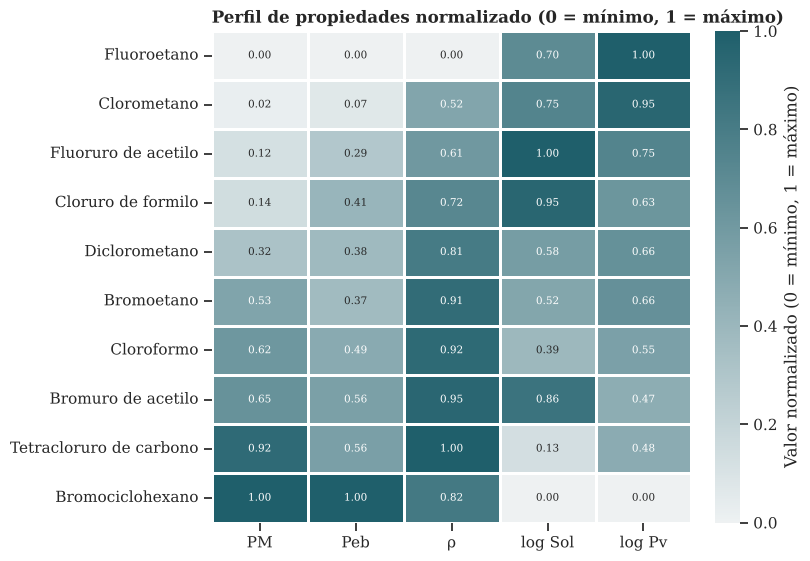

In [ ]:
# Relación química: perfil de cada sustancia en todas sus propiedades a la vez (cuál es la más pesada,
# la más volátil, la más soluble). Cada propiedad se escala de 0 (mínimo) a 1 (máximo).
# Decisión sobre vacíos (para que no aparezcan celdas grises "N/A" y se vean las 10 sustancias):
#   1) pKa se excluye porque no se comparan pKa entre sustancias;
#   2) se excluye toda propiedad a la que le falte el dato en alguna sustancia (se informa cuál).
m = sus.set_index('Sustancia')[[p for p in PROPS if p != 'pKa']].copy()
m['Pv'] = np.log10(m['Pv']); m['Sol'] = np.log10(m['Sol'])   # log10 para comparar órdenes de magnitud
faltan = m.isna().sum()                                        # vacíos por propiedad
quitar_prop = faltan[faltan > 0].index.tolist()                # propiedades incompletas
m = m.drop(columns=quitar_prop)                                # drop: se quitan esas columnas
print('Propiedades excluidas por datos faltantes:', {p: int(faltan[p]) for p in quitar_prop} or 'ninguna')

norm = (m - m.min()) / (m.max() - m.min())                     # normalización mín–máx por columna
norm = norm.loc[[s for s in ORDEN if s in norm.index]]         # filas en orden de PM
norm.columns = [{'Pv': 'log Pv', 'Sol': 'log Sol'}.get(x, x) for x in norm.columns]
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
sns.heatmap(norm, cmap=SEQ, vmin=0, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'Valor normalizado (0 = mínimo, 1 = máximo)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')                           # sin títulos repetidos
ax.set_title('Perfil de propiedades normalizado')
guardar(fig, '07_propiedades_normalizadas'); plt.show()

**Tipo de gráfica.** Mapa de calor: compara varias propiedades numéricas en las 10 sustancias a la vez. Cada columna se escala de 0 (mínimo) a 1 (máximo) y el número de cada celda es ese valor normalizado.

**Interpretación.** Se excluyeron Pf (falta en el cloruro de formilo) y μ (falta en 4 sustancias). El bromociclohexano tiene el mayor PM y Peb (1.00) y la menor solubilidad y presión de vapor (0.00); el fluoroetano está en el extremo contrario. El tetracloruro de carbono es el más denso (1.00, cuatro Cl).

### Gráfica 8. Líneas de doble eje: propiedades de las sustancias ordenadas por PM

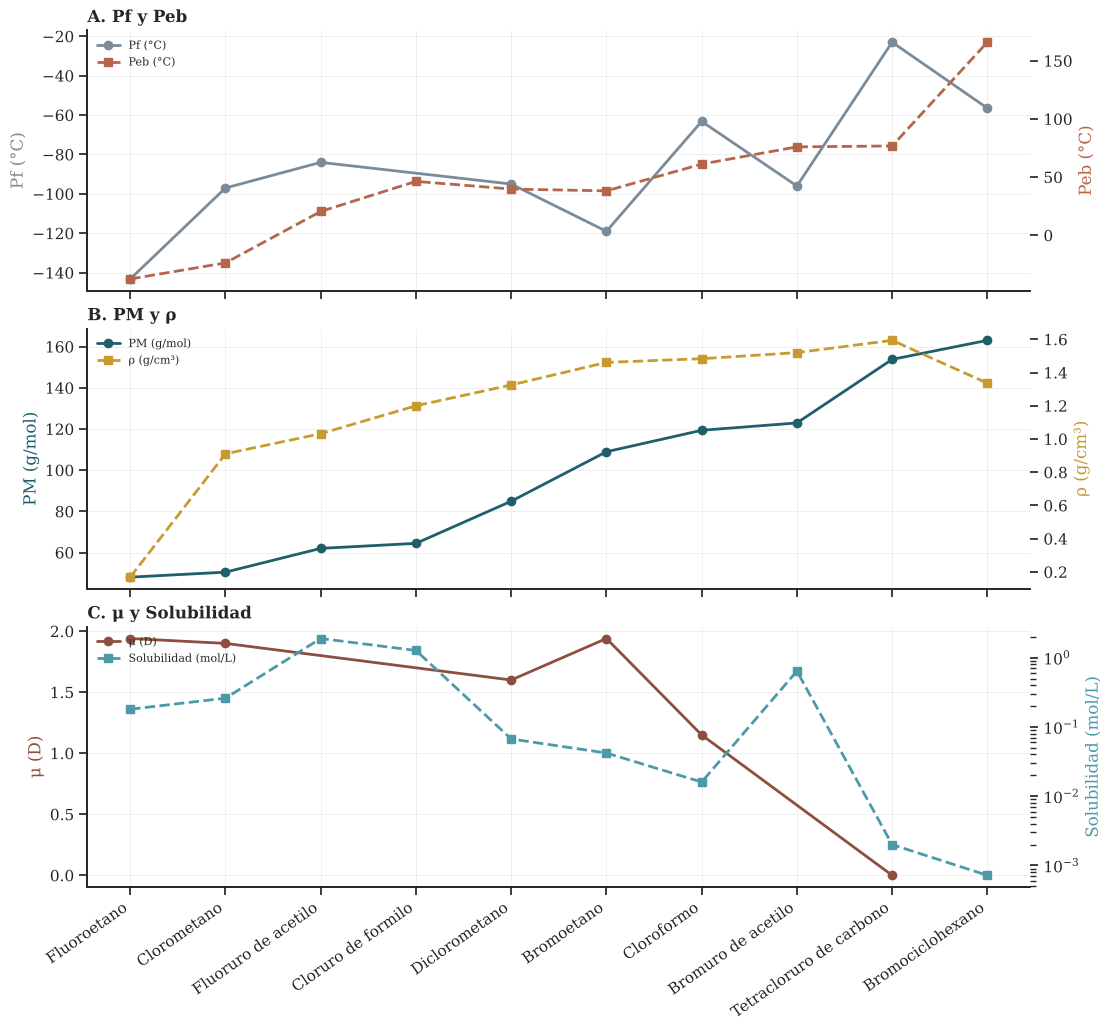

Pf–Peb: Spearman ρ = 0.78 (p = 0.013, n = 9)
PM–ρ: Spearman ρ = 0.88 (p = 0.001, n = 10)
μ–Sol: Spearman ρ = 0.67 (p = 0.148, n = 6)


In [ ]:
# Relación química: cómo cambian dos propiedades a la vez cuando aumenta el peso molecular.
# Doble eje porque las dos propiedades tienen escalas distintas (si no, una línea quedaría aplastada).
PARES = [('Pf', 'Peb'), ('PM', 'ρ'), ('μ', 'Sol')]                           # parejas elegidas a partir del mapa de correlación
MARCA = {0: 'o', 1: 's'}                     # marcador distinto para cada eje
d = sus.set_index('Sustancia').loc[ORDEN]       # filas en orden creciente de PM
x = np.arange(len(ORDEN))                       # posición de cada sustancia en el eje x
NOMBRE = [s.replace('Ácido ', '').capitalize() for s in ORDEN]   # nombres cortos para el eje
fig, axs = plt.subplots(3, 1, figsize=(11, 10.2), sharex=True, constrained_layout=True)
for i, (a, b) in enumerate(PARES):              # for: un panel por pareja
    ax = axs[i]
    ok = d[a].notna().values                    # solo sustancias con dato: la línea no se corta
    ax.plot(x[ok], d[a][ok], marker=MARCA[0], color=COL_VAR[a], lw=2, label=UNIDAD[a])
    ax.set_ylabel(UNIDAD[a], color=COL_VAR[a])
    ax2 = ax.twinx()                            # twinx: segundo eje y que comparte el eje x
    ok = d[b].notna().values
    ax2.plot(x[ok], d[b][ok], marker=MARCA[1], ls='--', color=COL_VAR[b], lw=2, label=UNIDAD[b])
    ax2.set_ylabel(UNIDAD[b], color=COL_VAR[b]); ax2.grid(False)
    for eje, var in ((ax, a), (ax2, b)):
        if var in ('Pv', 'Sol'):                # if: Pv y Sol abarcan varios órdenes de magnitud
            eje.set_yscale('log')
    ax.set_title(f'{chr(65 + i)}. {UNIDAD[a].split(" (")[0]} y {UNIDAD[b].split(" (")[0]}')
    lin = ax.get_legend_handles_labels(); lin2 = ax2.get_legend_handles_labels()
    ax.legend(lin[0] + lin2[0], lin[1] + lin2[1], loc='upper left', fontsize=8, frameon=False)
    ax.set_xticks(x); ax.set_xticklabels(NOMBRE, rotation=35, ha='right')
guardar(fig, '08_doble_eje_propiedades'); plt.show()
for a, b in PARES:                              # correlación de cada pareja en las 10 sustancias
    v = d[[a, b]].dropna()
    r, p = stats.spearmanr(v[a], v[b])          # Spearman: tendencia monótona, robusta con n = 10
    print(f'{a}–{b}: Spearman ρ = {r:.2f} (p = {p:.3f}, n = {len(v)})')

**Tipo de gráfica.** Gráfico de líneas con doble eje: las dos propiedades de cada panel tienen unidades y escalas distintas; el eje x son las sustancias ordenadas por PM.

**Interpretación.** **A:** Pf y Peb suben con el PM (Spearman ρ = 0.78, p = 0.013, n = 9). **B:** la densidad crece junto con el PM (ρ = 0.88, p = 0.001) y baja en el bromociclohexano, que tiene un solo Br y mucha parte hidrocarbonada. **C:** μ solo existe en 6 sustancias y su relación con la solubilidad no es significativa (ρ = 0.67, p = 0.15)

### Gráfica 9. Efecto del halógeno: punto de ebullición frente al peso molecular

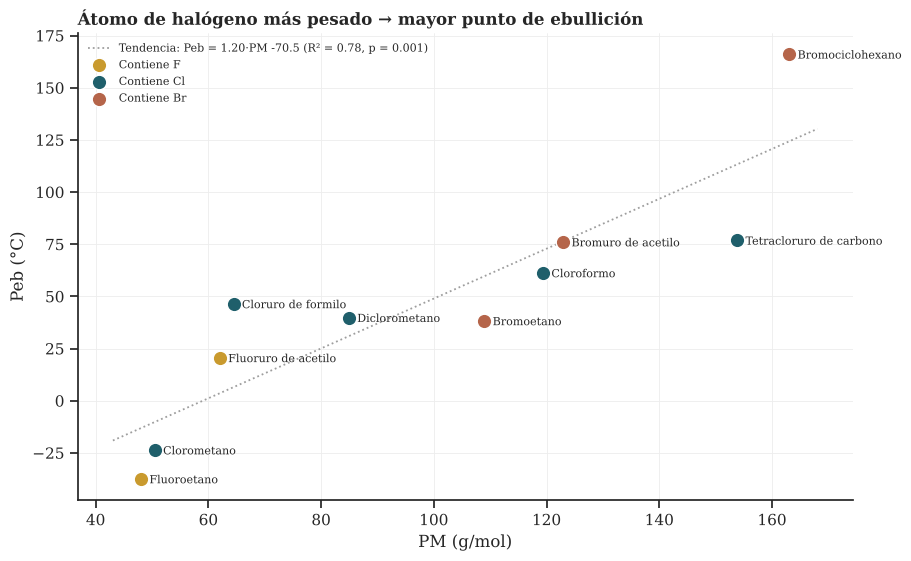

             PM   Peb
Halogeno             
Br        123.0  76.0
Cl         84.9  46.4
F          55.0  -8.5


In [ ]:
# Relación química: al cambiar F → Cl → Br el átomo es más grande y polarizable → fuerzas de London
# más fuertes → mayor Peb. También crece el PM, por eso se grafica Peb contra PM y se colorea por halógeno.
HALO = {'Clorometano': 'Cl', 'Diclorometano': 'Cl', 'Cloroformo': 'Cl', 'Tetracloruro de carbono': 'Cl',
        'Cloruro de formilo': 'Cl', 'Bromoetano': 'Br', 'Bromuro de acetilo': 'Br', 'Bromociclohexano': 'Br',
        'Fluoroetano': 'F', 'Fluoruro de acetilo': 'F'}   # halógeno presente en cada fórmula
COL_H = {'F': COL_VAR['ρ'], 'Cl': COL_VAR['PM'], 'Br': COL_VAR['Peb']}
d = sus.assign(Halogeno=sus['Sustancia'].map(HALO))
res = stats.linregress(d['PM'], d['Peb'])                  # tendencia general con las 10 sustancias
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
xs = np.linspace(d['PM'].min() - 5, d['PM'].max() + 5, 50)
ax.plot(xs, res.intercept + res.slope * xs, color=GRIS, ls=':', lw=1.3,
        label=f'Tendencia: Peb = {res.slope:.2f}·PM {res.intercept:+.1f} (R² = {res.rvalue**2:.2f}, p = {res.pvalue:.3f})')
for h in ['F', 'Cl', 'Br']:                                # for: un color por halógeno
    sub = d[d['Halogeno'] == h]
    ax.scatter(sub['PM'], sub['Peb'], s=110, color=COL_H[h], edgecolor='white', label=f'Contiene {h}', zorder=3)
for _, f in d.iterrows():
    ax.annotate(f['Sustancia'], (f['PM'], f['Peb']), xytext=(6, -3), textcoords='offset points', fontsize=8)
ax.set_xlabel(UNIDAD['PM']); ax.set_ylabel(UNIDAD['Peb'])
ax.set_title('Átomo de halógeno más pesado → mayor punto de ebullición'); ax.legend(fontsize=8, frameon=False)
guardar(fig, '09_efecto_halogeno'); plt.show()
print(d.groupby('Halogeno')[['PM', 'Peb']].median().round(1))

**Tipo de gráfica.** Diagrama de dispersión: relación entre dos variables numéricas; el color indica qué halógeno tiene la sustancia.

**Interpretación.** Al pasar de F a Cl y a Br aumentan el PM y el Peb (medianas: F 55 g/mol y −8.5 °C; Cl 85 g/mol y 46 °C; Br 123 g/mol y 76 °C). La tendencia es Peb = 1.20·PM − 70.5 (R² = 0.78, p = 0.001, n = 10): un halógeno más grande es más polarizable y genera fuerzas de London más fuertes. El bromociclohexano queda por encima de la recta (anillo de 6 carbonos) y el bromoetano por debajo (cadena corta).

### Gráfica 10. Tendencia: peso molecular frente a punto de ebullición de los productos

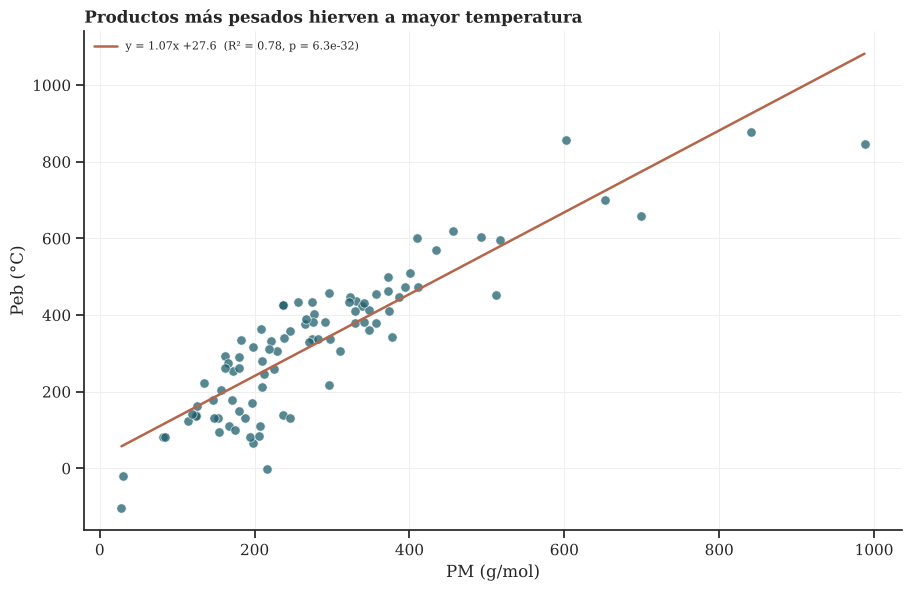

n = 93 | y = 1.067x +27.6 | R² = 0.783 | p = 6.33e-32
Pearson r = 0.88 (p = 6.3e-32) | Spearman ρ = 0.88 (p = 5.8e-31)


In [ ]:
# Relación química: a mayor PM, más electrones y superficie → fuerzas de London más fuertes → mayor Peb.
d = rx.dropna(subset=['PM', 'Peb'])
regresion(d, 'PM', 'Peb', UNIDAD['Peb'], 'Productos más pesados hierven a mayor temperatura', '10_PM_vs_Peb', grupo=None)   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión : dos variables numéricas; la regresión solo se usa en este tipo de gráfica.

**Interpretación.** Para los 93 productos con ambos datos, Peb ≈ 1.07·PM + 27.6 (R² = 0.78, p = 6×10⁻³²; Pearson y Spearman 0.88). Cada 100 g/mol adicionales suben el punto de ebullición unos 107 °C y el PM explica el 78 % de su variación.

### Gráfica 11. Relación estructural: peso molecular frente a densidad de los productos

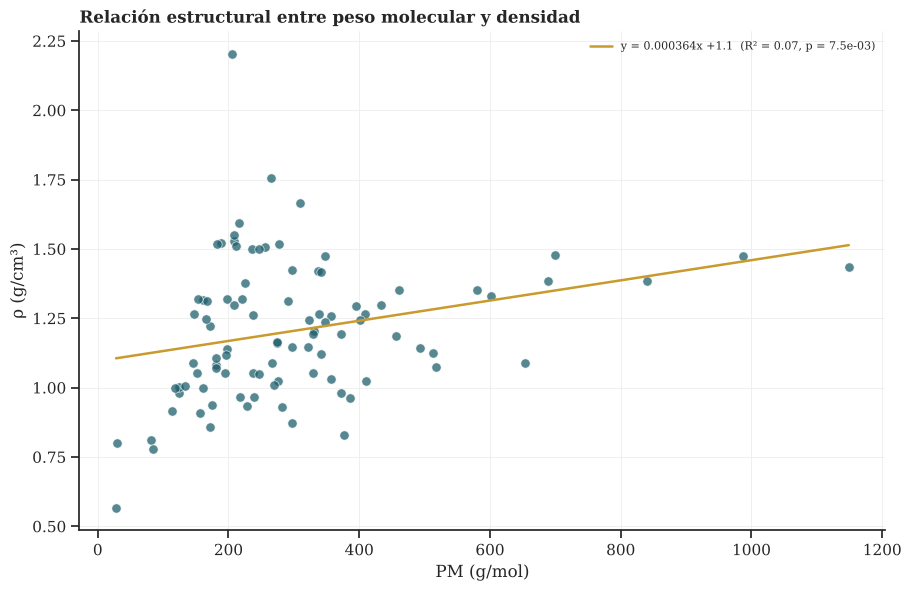

n = 95 | y = 0.0003641x +1.095 | R² = 0.074 | p = 7.46e-03
Pearson r = 0.27 (p = 7.5e-03) | Spearman ρ = 0.30 (p = 3.7e-03)


In [ ]:
# Relación química: la densidad depende de la masa por volumen molecular; átomos pesados (halógenos, O, metales) la suben más que el PM por sí solo.
d = rx.dropna(subset=['PM', 'ρ'])
regresion(d, 'PM', 'ρ', UNIDAD['ρ'], 'Relación estructural entre peso molecular y densidad', '11_PM_vs_densidad', grupo=None)   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión (*Scatterplot*).

**Interpretación.** La relación es débil (R² = 0.07, p = 0.007, n = 95; Spearman 0.30): el PM casi no explica la densidad de los productos. Lo que la sube es el contenido de halógeno: el punto de 2.20 g/cm³ es el 1,1-dibromo-1-fluoroetano, con tres halógenos en solo 206 g/mol.

### Gráfica 12. Volatilidad: punto de ebullición frente a presión de vapor

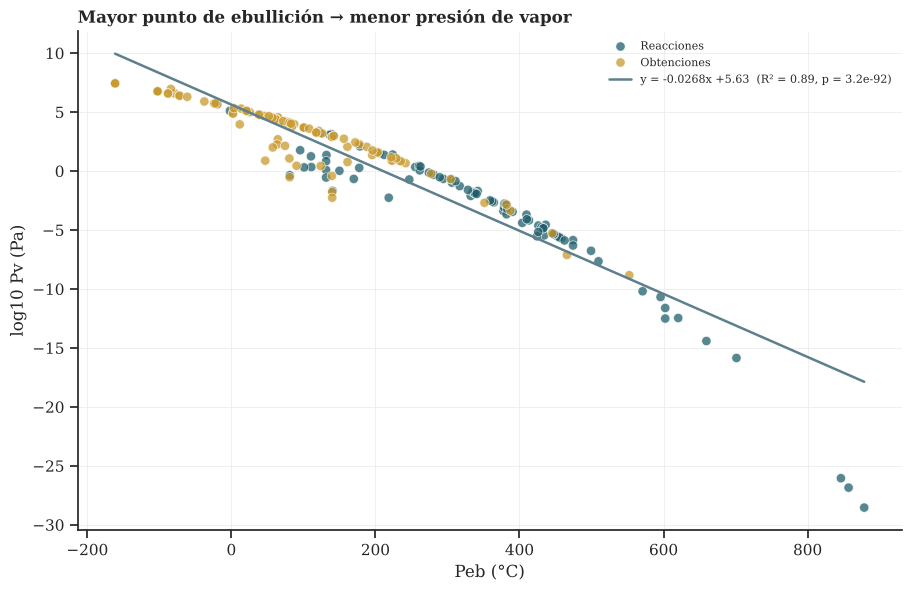

n = 191 | y = -0.02676x +5.634 | R² = 0.889 | p = 3.21e-92
Pearson r = -0.94 (p = 3.2e-92) | Spearman ρ = -0.95 (p = 2.6e-101)


In [ ]:
# Relación química: ambas miden la fuerza de las interacciones intermoleculares; si cuesta más separar las moléculas (Peb alto), pocas pasan al vapor (Pv baja). Se usan productos y reactivos; Pv en log10.
d = ambos.dropna(subset=['Peb', 'Pv'])
d = d[d['Pv'] > 0].assign(Pv=np.log10(d['Pv'][d['Pv'] > 0]))   # log10: Pv abarca muchos órdenes de magnitud
regresion(d, 'Peb', 'Pv', 'log10 Pv (Pa)', 'Mayor punto de ebullición → menor presión de vapor', '12_Peb_vs_Pv', grupo='Conjunto')   # función definida en la sección 2

**Tipo de gráfica.** Diagrama de dispersión con recta de regresión; Pv en log10 porque abarca muchos órdenes de magnitud.

**Interpretación.** Es la relación más fuerte del proyecto: log Pv = −0.027·Peb + 5.63 (R² = 0.89, Pearson −0.94, Spearman −0.95, n = 191). Cada 100 °C más de Peb, la Pv baja unas 500 veces (2.7 unidades de log). Reactivos de obtenciones y productos de reacciones siguen la misma línea, lo que confirma que es una propiedad física general.

### Gráfica 13. Distribución de la temperatura máxima de reacción

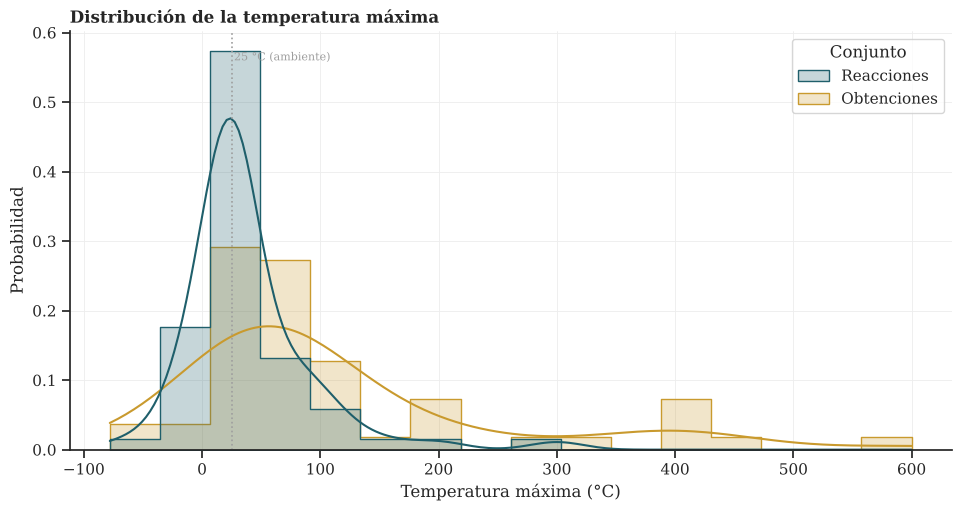

Obtenciones: n = 55 | mediana = 70 °C | P(T > 25 °C) = 0.73 [0.60–0.83] | sin T numérica: 45
Reacciones: n = 68 | mediana = 25 °C | P(T > 25 °C) = 0.31 [0.21–0.43] | sin T numérica: 32


In [ ]:
# Relación química: cuánta energía térmica necesitan las reacciones; T > 25 °C indica calentamiento.
fig, ax = plt.subplots(figsize=(9.5, 5), constrained_layout=True)
sns.histplot(data=ambos.dropna(subset=['T_max']), x='T_max', hue='Conjunto', palette=COL_CONJ, bins=16,
             stat='probability', common_norm=False, kde=True, element='step', alpha=0.25, ax=ax)
ax.axvline(25, color=GRIS, ls=':', lw=1.2); ax.text(27, ax.get_ylim()[1] * 0.93, '25 °C (ambiente)', fontsize=8, color=GRIS)
ax.set_xlabel('Temperatura máxima (°C)'); ax.set_ylabel('Probabilidad'); ax.set_title('Distribución de la temperatura máxima')
guardar(fig, '13_distribucion_temperatura'); plt.show()
for conj, g in ambos.groupby('Conjunto'):
    t = g['T_max'].dropna()
    p, lo, hi = wilson((t > 25).sum(), len(t))
    print(f'{conj}: n = {len(t)} | mediana = {t.median():.0f} °C | P(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}] | sin T numérica: {g["T_max"].isna().sum()}')

**Tipo de gráfica.** Histograma con curva de densidad: distribución de una variable numérica continua; la línea punteada marca 25 °C (ambiente).

**Interpretación.** Las reacciones de los halogenados ocurren sobre todo a temperatura ambiente (mediana 25 °C; P(T > 25 °C) = 0.31, IC 0.21–0.43), porque el enlace C–X ya es reactivo. Las obtenciones necesitan más calor (mediana 70 °C; P = 0.73, IC 0.60–0.83): las halogenaciones en fase gaseosa se hacen entre 400 y 600 °C (O-057, O-070, O-031 y O-087).

### Gráfica 14. Temperatura de las reacciones con calentamiento, según el medio

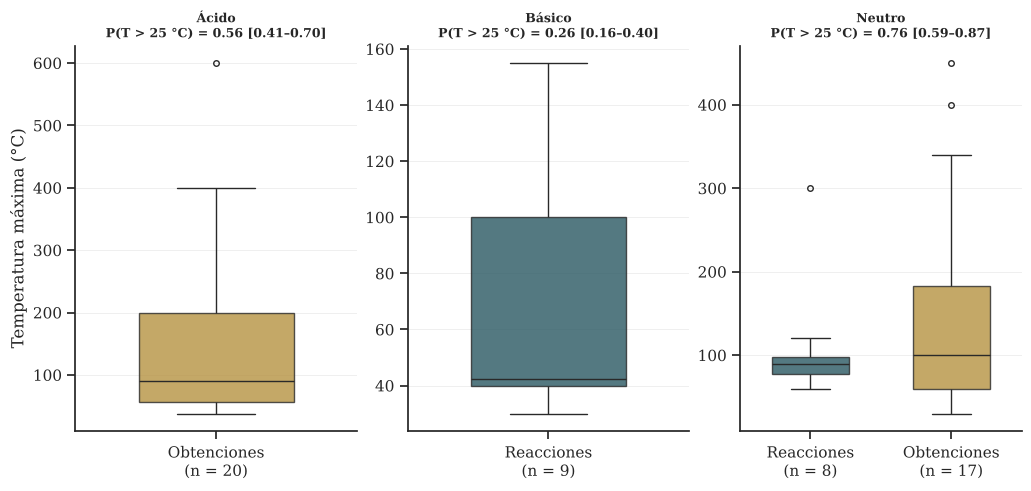

Datos por caja (T > 25 °C):
Conjunto  Obtenciones  Reacciones
Medio                            
Básico              3           9
Neutro             17           8
Ácido              20           4
                    count    50%   min    max
Medio  Conjunto                              
Básico Obtenciones    3.0  100.0  60.0  100.0
       Reacciones     9.0   42.0  30.0  155.0
Neutro Obtenciones   17.0  100.0  30.0  450.0
       Reacciones     8.0   90.0  60.0  300.0
Ácido  Obtenciones   20.0   90.0  38.0  600.0
       Reacciones     4.0   85.0  65.0  200.0


In [ ]:
# Relación química: cuando una reacción necesita calor, ¿a qué temperatura se hace en cada medio?
# Muchas reacciones son a 25 °C (ambiente); esos valores iguales aplastan la caja, por eso se filtran:
# su frecuencia se resume en P(T > 25 °C) del título y la caja muestra solo las que se calientan.
conT = ambos.dropna(subset=['T_max'])                     # reacciones con temperatura numérica
cal = conT[conT['T_max'] > 25]                            # solo las que se calientan
n_caja = cal.groupby(['Medio', 'Conjunto']).size()        # datos en cada caja
MED_T = [m for m in MEDIOS if n_caja.get(m, pd.Series()).max() >= 5]   # al menos una caja con 5 datos
fig, axs = plt.subplots(1, len(MED_T), figsize=(3.4 * len(MED_T), 4.8), constrained_layout=True)
for ax, m in zip(axs, MED_T):                             # un panel por medio, cada uno con su escala
    grupos = [g for g in ['Reacciones', 'Obtenciones'] if n_caja.get((m, g), 0) >= 5]
    d = cal[(cal['Medio'] == m) & cal['Conjunto'].isin(grupos)]
    sns.boxplot(data=d, x='Conjunto', y='T_max', order=grupos, hue='Conjunto', palette=COL_CONJ,
                width=0.55, fliersize=4, legend=False, boxprops={'alpha': 0.8}, ax=ax)
    ax.set_xticks(range(len(grupos)))
    ax.set_xticklabels([f'{g}\n(n = {n_caja[(m, g)]})' for g in grupos])
    todos = conT[conT['Medio'] == m]
    p, lo, hi = wilson((todos['T_max'] > 25).sum(), len(todos))
    ax.set_title(f'{m}\nP(T > 25 °C) = {p:.2f} [{lo:.2f}–{hi:.2f}]', fontsize=9, loc='center')
    ax.set_xlabel(''); ax.set_ylabel('Temperatura máxima (°C)' if m == MED_T[0] else '')
guardar(fig, '14_temperatura_por_medio'); plt.show()
print('Datos por caja (T > 25 °C):'); print(n_caja.unstack(fill_value=0))
print(cal.groupby(['Medio', 'Conjunto'])['T_max'].describe()[['count', '50%', 'min', 'max']].round(0).to_string())

**Tipo de gráfica.** Diagrama de caja: mediana, cuartiles y atípicos de cada grupo; cada medio tiene su propio eje y.

**Interpretación.** Solo se dibujan las reacciones que se calientan (T > 25 °C) y cajas con al menos 5 datos; la probabilidad de calentar está en el título de cada panel. En medio neutro se calienta con más frecuencia (0.76, IC 0.59–0.87) que en básico (0.26, IC 0.16–0.40): las sustituciones en medio básico avanzan a temperatura ambiente. En medio ácido las obtenciones llegan a 600 °C (O-087, bromación de metano) y en neutro a 450 °C (O-031, clorinólisis); son los atípicos.

### Gráfica 15. Comparación de distribuciones: reactivos (obtenciones) frente a productos (reacciones)

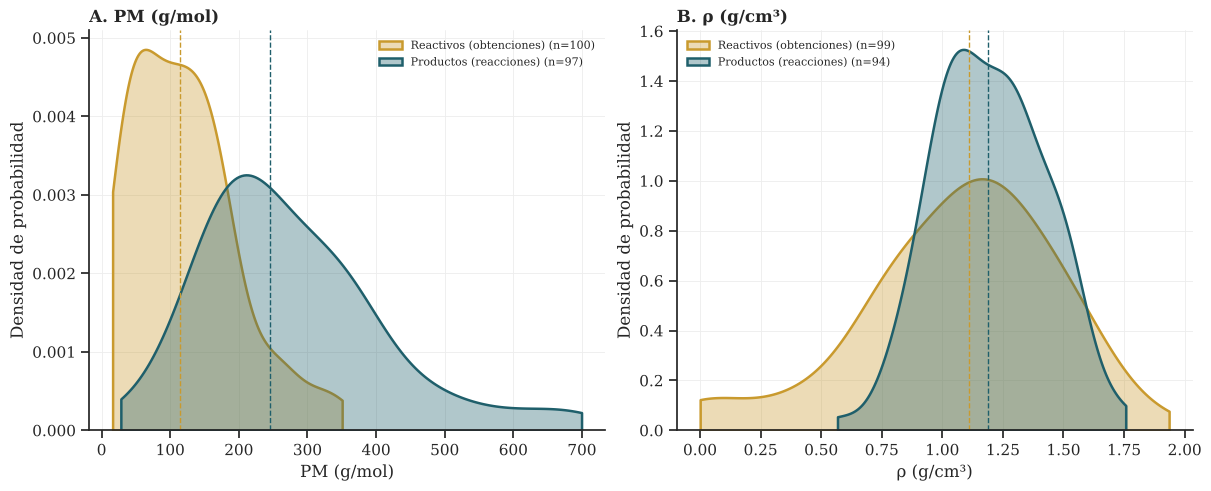

PM: mediana reactivos = 115 | productos = 251 | Mann-Whitney p = 1.30e-19
ρ: mediana reactivos = 1.11 | productos = 1.19 | Mann-Whitney p = 4.06e-02


In [ ]:
# Relación química: al reaccionar, la sustancia se convierte en productos más grandes o más pequeños;
# se comparan las distribuciones (densidad de probabilidad) de PM y ρ de reactivos y productos.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, var in zip(axs, ['PM', 'ρ']):                      # un panel por propiedad
    tope = ambos[var].quantile(0.97) * 1.2                  # se recorta el 3 % más extremo solo en el dibujo
    for conj, et in (('Obtenciones', 'Reactivos (obtenciones)'), ('Reacciones', 'Productos (reacciones)')):
        v = ambos.loc[(ambos['Conjunto'] == conj) & (ambos[var] <= tope), var].dropna()
        sns.kdeplot(v, fill=True, alpha=0.35, color=COL_CONJ[conj], lw=1.8, cut=0, ax=ax, label=f'{et} (n={len(v)})')
        ax.axvline(v.median(), color=COL_CONJ[conj], ls='--', lw=1)    # línea = mediana
    ax.set_xlabel(UNIDAD[var]); ax.set_ylabel('Densidad de probabilidad'); ax.legend(fontsize=8, frameon=False)
    ax.set_title(f'{chr(65 + list(axs).index(ax))}. {UNIDAD[var]}')
guardar(fig, '15_reactivos_vs_productos'); plt.show()
for var in ['PM', 'ρ']:                                    # prueba de Mann-Whitney (no supone normalidad)
    a = ob[var].dropna(); b = rx[var].dropna()
    print(f'{var}: mediana reactivos = {a.median():.3g} | productos = {b.median():.3g} | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2e}')

**Tipo de gráfica.** Gráfico de densidad: compara la forma de dos distribuciones numéricas; la línea punteada es la mediana.

**Interpretación.** Los productos son más pesados que los reactivos de obtención (mediana 251 frente a 115 g/mol, Mann-Whitney p = 1×10⁻¹⁹): los reactivos para obtener un halogenado son pequeños (alcanos, alcoholes, alquenos), mientras que al reaccionar el halogenado se une a moléculas grandes. La densidad es un poco mayor en los productos (1.19 frente a 1.11 g/cm³), pero la diferencia es pequeña(p = 0.04).

### Gráfica 16. Cambio de peso molecular en las reacciones (ΔPM = producto − sustancia)

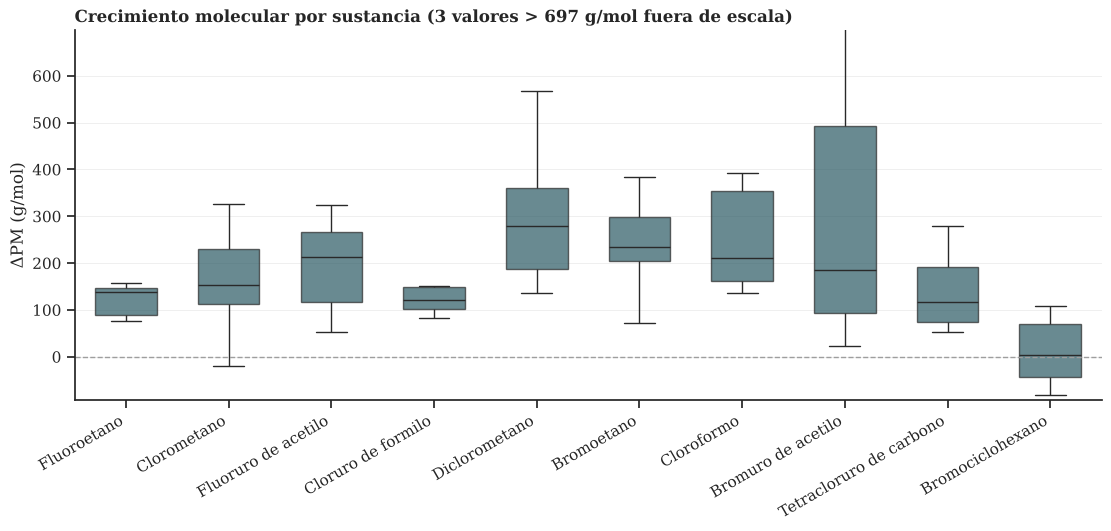

P(ΔPM > 0) = 0.93 de 100 reacciones
Sustancia
Fluoroetano                139.0
Clorometano                153.0
Fluoruro de acetilo        212.0
Cloruro de formilo         121.0
Diclorometano              280.0
Bromoetano                 235.0
Cloroformo                 210.0
Bromuro de acetilo         185.0
Tetracloruro de carbono    118.0
Bromociclohexano             5.0


In [ ]:
# Relación química: si la reacción añade átomos (adición, acoplamiento, acilación) el producto pesa más;
# si los quita (eliminación, reducción de grupos, ruptura) pesa menos. ΔPM > 0 = crecimiento molecular.
rx['ΔPM'] = rx['PM'] - rx['Sustancia'].map(sus.set_index('Sustancia')['PM'])
tope = rx['ΔPM'].quantile(0.97) * 1.2                      # escala: se recorta el 3 % más extremo
fig, ax = plt.subplots(figsize=(11, 5.2), constrained_layout=True)
sns.boxplot(data=rx, x='Sustancia', y='ΔPM', order=ORDEN, color=COL_VAR['PM'], fliersize=0, width=0.6,
            boxprops={'alpha': 0.7}, ax=ax)
ax.axhline(0, color=GRIS, ls='--', lw=1)                    # referencia: sin cambio de masa
ax.set_ylim(min(rx['ΔPM'].min() * 1.15, -50), tope); ax.set_xlabel(''); ax.set_ylabel('ΔPM (g/mol)')
fuera = int((rx['ΔPM'] > tope).sum())
ax.set_title(f'Crecimiento molecular por sustancia')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
guardar(fig, '16_cambio_peso_molecular'); plt.show()
print(f"P(ΔPM > 0) = {(rx['ΔPM'] > 0).mean():.2f} de {rx['ΔPM'].notna().sum()} reacciones")
print(rx.groupby('Sustancia')['ΔPM'].median().reindex(ORDEN).round(0).to_string())

**Tipo de gráfica.** Diagrama de caja: distribución del cambio de peso molecular (ΔPM) por sustancia.

**Interpretación.** El 93 % de las reacciones aumentan el PM: el halógeno sale y entra un fragmento más grande. El diclorometano (+280 g/mol) y el bromoetano (+235) tienen las medianas más altas. El bromociclohexano casi no cambia (+5): en varias reacciones el Br (80 g/mol) se cambia por un grupo de masa parecida o se pierde (eliminación y reducción).

### Gráfica 17. Probabilidad de usar catalizador y de calentar, por sustancia

**Procedimiento.**
1. Para cada sustancia (conjunto Reacciones) se calculan dos proporciones: la de reacciones que **usan catalizador** y la de reacciones con **calentamiento (T > 25 °C)**. Para la segunda solo cuentan las reacciones que tienen temperatura.
2. Con `wilson` se obtiene el **IC 95 %** de cada proporción, que se dibuja como barra de error.
3. Se dibujan **barras agrupadas** por sustancia (gris oscuro = catalizador, malva = calor), con el eje y de 0 a 1.
4. Se imprimen las probabilidades globales y las **condicionales**: P(catalizador | calor) y P(catalizador | sin calor), que indican si el catalizador y el calentamiento tienden a usarse juntos.

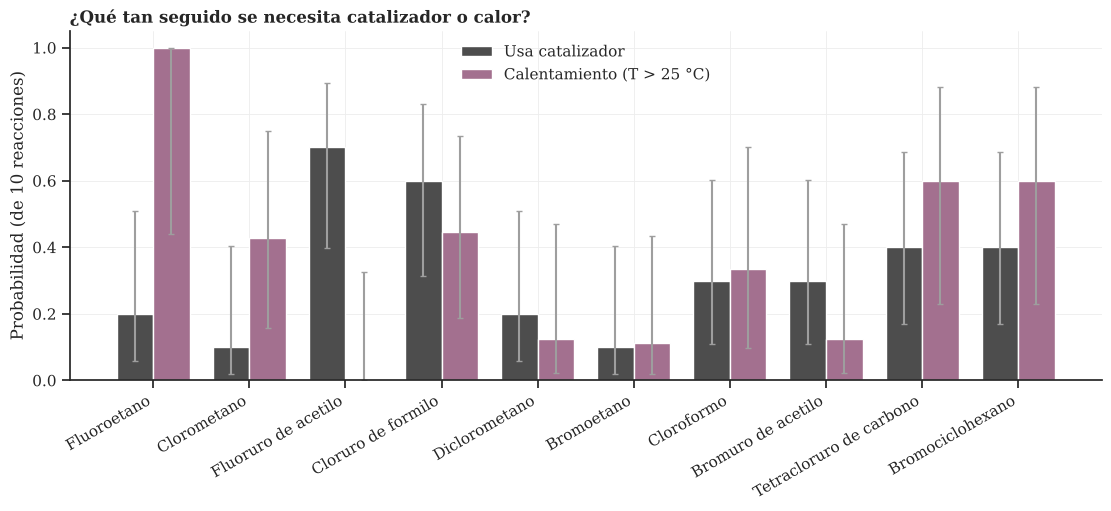

P(catalizador) = 0.33 (n = 100) | P(T > 25 °C) = 0.31 (n = 68)
P(catalizador | calor) = 0.62 (n = 21) | P(catalizador | sin calor) = 0.30 (n = 47)


In [ ]:
# Relación química: las sustancias poco reactivas necesitan catalizador o calor para reaccionar.
# Son variables sí/no (categóricas) → proporción con IC 95 % de Wilson, en barras agrupadas.
filas = []
for s_, g in rx.groupby('Sustancia'):
    for var, et in (('Usa catalizador', 'Usa catalizador'), ('Calor', 'Calentamiento (T > 25 °C)')):
        if var == 'Usa catalizador':                  # if: catalizador se conoce en todas las reacciones
            serie = g['Usa catalizador']
        else:                                         # el calor solo se evalúa donde hay T numérica
            serie = g['T_max'].dropna() > 25
        p, lo, hi = wilson(int(serie.sum()), len(serie))
        filas.append(dict(Sustancia=s_, Variable=et, P=p, lo=lo, hi=hi))
t = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(ORDEN)); w = 0.38
for i, (et, col) in enumerate(zip(t['Variable'].unique(), [COL_SI['cat'], COL_SI['calor']])):
    s = t[t['Variable'] == et].set_index('Sustancia').reindex(ORDEN)
    ax.bar(x + (i - 0.5) * w, s['P'], width=w, color=col, label=et,
           yerr=[s['P'] - s['lo'], s['hi'] - s['P']], error_kw={'ecolor': GRIS, 'capsize': 2})
ax.set_xticks(x); ax.set_xticklabels(ORDEN, rotation=30, ha='right'); ax.set_xlabel('')
ax.set_ylim(0, 1.05); ax.set_ylabel('Probabilidad (de 10 reacciones)'); ax.legend(frameon=False)
ax.set_title('¿Qué tan seguido se necesita catalizador o calor?')
guardar(fig, '17_prob_catalizador_calor'); plt.show()
conT = rx.dropna(subset=['T_max'])                    # reacciones con temperatura numérica
cal = conT['T_max'] > 25
print(f"P(catalizador) = {rx['Usa catalizador'].mean():.2f} (n = {len(rx)}) | P(T > 25 °C) = {cal.mean():.2f} (n = {len(conT)})")
print(f"P(catalizador | calor) = {conT.loc[cal, 'Usa catalizador'].mean():.2f} (n = {cal.sum()}) | P(catalizador | sin calor) = {conT.loc[~cal, 'Usa catalizador'].mean():.2f} (n = {(~cal).sum()})")

**Tipo de gráfica.** Barras agrupadas con barras de error: variables sí/no expresadas como proporción con su IC 95 % de Wilson.

**Interpretación.** Solo el 33 % de las reacciones usa catalizador y el 31 % (de 68 con T) se calienta: los halogenados reaccionan con facilidad. Cuando hay calentamiento el catalizador es más probable (0.62, n = 21) que sin él (0.30, n = 47). El fluoruro de acetilo (0.7) y el cloruro de formilo (0.6) son los que más usan catalizador. Las barras de error son grandes porque hay 10 reacciones por sustancia.

### Gráficas 18 y 19. Interactivas (Plotly)

In [ ]:
# Relación química: la misma tendencia PM–Peb, pero al pasar el cursor se ve el producto y la reacción.
d = rx.dropna(subset=['PM', 'Peb']).copy()
fig = px.scatter(d, x='PM', y='Peb', color='Tipo de reacción', hover_data=['Producto', 'Sustancia', 'ID', 'Medio'],
                 labels={'PM': UNIDAD['PM'], 'Peb': UNIDAD['Peb']}, height=550,
                 title='Productos: PM frente a Peb (pasa el cursor sobre los puntos)',
                 color_discrete_sequence=list(COL_VAR.values()))
fig.write_html(f'{CARPETA}/18_interactivo_PM_Peb.html'); fig.show()

# Gráfica solar: se lee del centro hacia afuera: sustancia → medio → tipo de reacción.
fig2 = px.sunburst(rx.fillna({'Medio': 'Sin dato'}), path=['Sustancia', 'Medio', 'Tipo de reacción'], height=600,
                   title='Sustancia → medio → tipo de reacción', color_discrete_sequence=list(COL_VAR.values()))
fig2.write_html(f'{CARPETA}/19_interactivo_solar.html'); fig2.show()

**Tipo de gráfica.** Dispersión interactiva y diagrama solar: jerarquía de tres niveles categóricos leída del centro hacia afuera.

**Interpretación.** **Dispersión interactiva:** al pasar el cursor se ve el producto y la reacción de cada punto, útil para explicar los atípicos en la exposición. **Diagrama solar:** sustancia → medio → tipo de reacción; por ejemplo, se ve que el bromoetano reacciona en medio básico por sustitución nucleofílica.

## 4. Descarga de las figuras

**Procedimiento.** `shutil.make_archive` comprime la carpeta `figuras_halogenados/` en un archivo **.zip**. Si el cuaderno corre en Colab, `files.download` lo descarga al computador. Ese .zip contiene las imágenes que se usan en el informe de LaTeX.

In [ ]:
# Comprime la carpeta de figuras en un .zip y lo descarga (las figuras van al informe en LaTeX).
shutil.make_archive(CARPETA, 'zip', CARPETA)      # crea figuras_halogenados.zip
if EN_COLAB:                                      # if: la descarga automática solo existe en Colab
    files.download(f'{CARPETA}.zip')
print('Figuras guardadas en', CARPETA)

Figuras guardadas en figuras_halogenados
